# Assignment 60 — Week 7, Day 1
## Topic: Deep Learning — Linguistics with NLP

**Objective:** Complete the exercise on linguistics using machine learning in Python.

**Reference:** https://medium.com/towards-artificial-intelligence/natural-language-processing-nlp-with-python-tutorial-for-beginners-1f54e610a1a0

**Natural Language Processing (NLP)** is the part of AI that lets computers work with human language. Before a machine learning model can use text, the text has to be broken down using ideas from **linguistics**: words, word forms, parts of speech, phrases and named things.

Following the Towards AI NLP tutorial, this notebook uses the **NLTK** library to cover tokenisation, stop words, stemming, lemmatisation, part-of-speech tagging, chunking, chinking, named entity recognition and WordNet.

**Requirements:** `pip install nltk`, then the data packages downloaded in the first cell.

**Install check and download the NLTK data**

In [1]:
import nltk

for package in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger",
                "averaged_perceptron_tagger_eng", "maxent_ne_chunker", "maxent_ne_chunker_tab", "words", "tagsets_json"]:
    nltk.download(package, quiet=True)

print("NLTK", nltk.__version__, "ready")

NLTK 3.10.3 ready


**Explanation:** NLTK keeps its models and word lists as separate data packages. They are downloaded once and then reused.

**Diagram:** Each linguistic step turns raw text into more structured information.

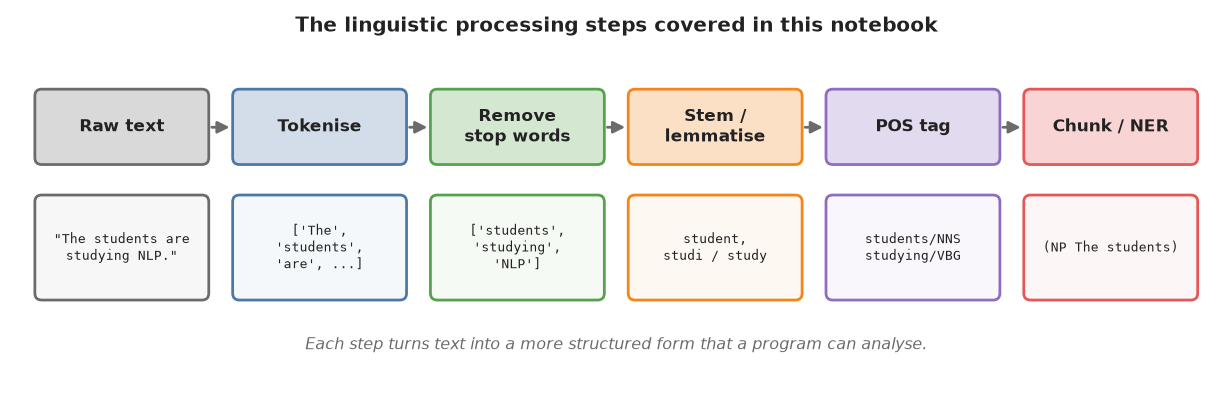

**Sentence and word tokenisation**

In [2]:
from nltk.tokenize import sent_tokenize, word_tokenize

text = """Natural language processing helps computers understand human language. Researchers at Stanford University and Google are building better language models. These models are learning grammar, meaning and context from millions of sentences. In Pakistan, students at NAVTTC are studying how machines read and write text."""

sentences = sent_tokenize(text)
print("Number of sentences:", len(sentences))
for s in sentences:
    print("-", s)

words = word_tokenize(sentences[1])
print(words)

Number of sentences: 4
- Natural language processing helps computers understand human language.
- Researchers at Stanford University and Google are building better language models.
- These models are learning grammar, meaning and context from millions of sentences.
- In Pakistan, students at NAVTTC are studying how machines read and write text.
['Researchers', 'at', 'Stanford', 'University', 'and', 'Google', 'are', 'building', 'better', 'language', 'models', '.']


**Explanation:** Tokenisation splits text into units. sent_tokenize() splits it into sentences, and word_tokenize() splits a sentence into words and punctuation marks, which are called tokens.

**Remove stop words**

In [3]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

sentence = "These models are learning grammar, meaning and context from millions of sentences."
stop_words = set(stopwords.words("english"))

tokens = word_tokenize(sentence)
filtered = [w for w in tokens if w.lower() not in stop_words and w.isalpha()]

print("Tokens:  ", tokens)
print("Filtered:", filtered)
print("Some stop words:", sorted(stop_words)[:12])

Tokens:   ['These', 'models', 'are', 'learning', 'grammar', ',', 'meaning', 'and', 'context', 'from', 'millions', 'of', 'sentences', '.']
Filtered: ['models', 'learning', 'grammar', 'meaning', 'context', 'millions', 'sentences']
Some stop words: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any']


**Explanation:** Stop words are very common words such as 'are', 'and' and 'from' that carry little meaning on their own. Removing them, together with punctuation, keeps the words that describe the content.

**Diagram:** How a stemmer and a lemmatiser reduce the same words.

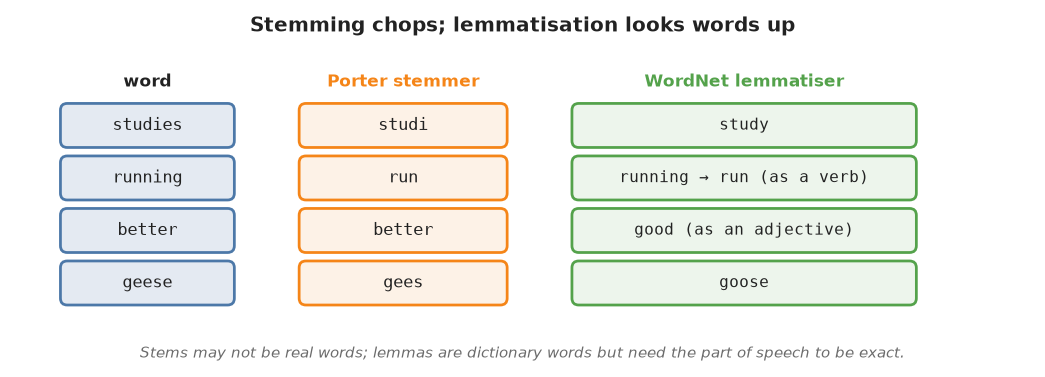

**Stemming**

In [4]:
from nltk.stem import PorterStemmer, SnowballStemmer

words = ["studies", "studying", "studied", "running", "runner", "easily", "fairly", "connection", "connected"]

porter = PorterStemmer()
snowball = SnowballStemmer("english")

for w in words:
    print(f"{w:12} porter: {porter.stem(w):10} snowball: {snowball.stem(w)}")

studies      porter: studi      snowball: studi
studying     porter: studi      snowball: studi
studied      porter: studi      snowball: studi
running      porter: run        snowball: run
runner       porter: runner     snowball: runner
easily       porter: easili     snowball: easili
fairly       porter: fairli     snowball: fair
connection   porter: connect    snowball: connect
connected    porter: connect    snowball: connect


**Explanation:** Stemming cuts words down to a common root by removing endings such as -ing, -ed and -ion. It is fast but rough: 'studies' becomes 'studi', which is not a real word.

**Lemmatisation**

In [5]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

print(lemmatizer.lemmatize("studies"))
print(lemmatizer.lemmatize("geese"))
print(lemmatizer.lemmatize("running"))
print(lemmatizer.lemmatize("running", pos="v"))
print(lemmatizer.lemmatize("better", pos="a"))

study
goose
running
run
good


**Explanation:** Lemmatisation uses the WordNet dictionary to find a word's base form (lemma), so the result is always a real word: 'studies' → 'study', 'geese' → 'goose'. Giving the part of speech improves it: 'running' as a verb becomes 'run', and 'better' as an adjective becomes 'good'.

**Part-of-speech (POS) tagging**

In [6]:
import nltk
from nltk.tokenize import word_tokenize

sentence = "Researchers at Stanford University are building better language models."
tagged = nltk.pos_tag(word_tokenize(sentence))

for word, tag in tagged:
    print(f"{word:12} {tag}")

print()
nltk.help.upenn_tagset("VBG")

Researchers  NNS
at           IN
Stanford     NNP
University   NNP
are          VBP
building     VBG
better       JJR
language     NN
models       NNS
.            .

VBG: verb, present participle or gerund
    telegraphing stirring focusing angering judging stalling lactating
    hankerin' alleging veering capping approaching traveling besieging
    encrypting interrupting erasing wincing ...


**Explanation:** POS tagging labels each word with its grammatical role, using the Penn Treebank tags: NNP is a proper noun, NNS a plural noun, VBP and VBG are verbs, JJR a comparative adjective. help.upenn_tagset() explains any tag.

**Diagram:** A chunk grammar groups determiners, adjectives and nouns into noun phrases.

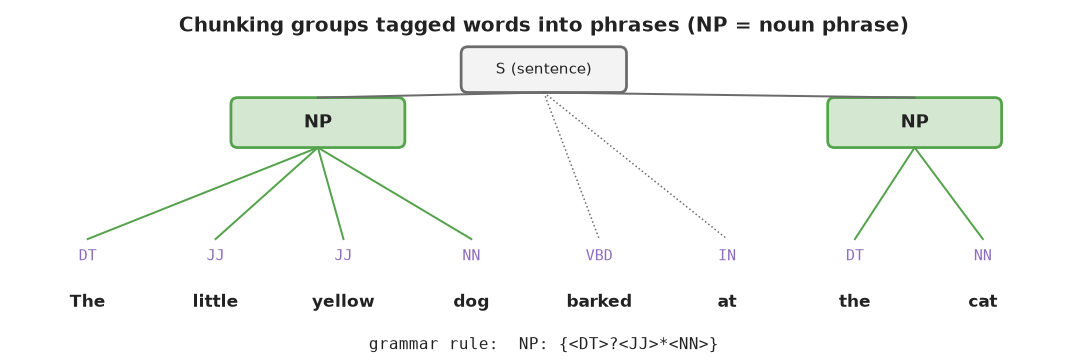

**Chunking: find noun phrases**

In [7]:
import nltk
from nltk.tokenize import word_tokenize

sentence = "The little yellow dog barked at the cat."
tagged = nltk.pos_tag(word_tokenize(sentence))

grammar = "NP: {<DT>?<JJ>*<NN>}"
parser = nltk.RegexpParser(grammar)
tree = parser.parse(tagged)

print(tree)
print([" ".join(w for w, t in subtree.leaves()) for subtree in tree.subtrees() if subtree.label() == "NP"])

(S
  (NP The/DT little/JJ yellow/JJ dog/NN)
  barked/VBD
  at/IN
  (NP the/DT cat/NN)
  ./.)
['The little yellow dog', 'the cat']


**Explanation:** Chunking groups tagged words into phrases. The grammar NP: {<DT>?<JJ>*<NN>} means an optional determiner, any number of adjectives, then a noun. It finds the noun phrases 'The little yellow dog' and 'the cat'.

**Chinking: remove words from a chunk**

In [8]:
import nltk
from nltk.tokenize import word_tokenize

sentence = "The little yellow dog barked at the cat."
tagged = nltk.pos_tag(word_tokenize(sentence))

grammar = r'''
Chunk: {<.*>+}
       }<VBD|IN>+{
'''
tree = nltk.RegexpParser(grammar).parse(tagged)
print(tree)

(S
  (Chunk The/DT little/JJ yellow/JJ dog/NN)
  barked/VBD
  at/IN
  (Chunk the/DT cat/NN ./.))


**Explanation:** Chinking is the opposite of chunking: first everything is chunked with {<.*>+}, then the }<VBD|IN>+{ rule removes past-tense verbs and prepositions, which splits the sentence into the parts around 'barked at'.

**Named entity recognition (NER)**

In [9]:
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize

text = """Natural language processing helps computers understand human language. Researchers at Stanford University and Google are building better language models. These models are learning grammar, meaning and context from millions of sentences. In Pakistan, students at NAVTTC are studying how machines read and write text."""

for sentence in sent_tokenize(text):
    tree = nltk.ne_chunk(nltk.pos_tag(word_tokenize(sentence)))
    for subtree in tree.subtrees():
        if subtree.label() != "S":
            print(subtree.label(), "->", " ".join(w for w, t in subtree.leaves()))

ORGANIZATION -> Stanford University
GPE -> Google


GPE -> Pakistan
ORGANIZATION -> NAVTTC


**Explanation:** NER finds names of real-world things and labels them, for example ORGANIZATION, PERSON and GPE (a geo-political entity such as a country). NLTK's built-in chunker is a classic statistical model, so it is useful but not perfect: here it finds Stanford University, Pakistan and NAVTTC correctly but labels Google as a GPE instead of an organisation.

**WordNet: definitions, synonyms and antonyms**

In [10]:
from nltk.corpus import wordnet

syn = wordnet.synsets("program")[0]
print("Definition:", syn.definition())
print("Example:", syn.examples())

synonyms, antonyms = set(), set()
for s in wordnet.synsets("good"):
    for lemma in s.lemmas():
        synonyms.add(lemma.name())
        if lemma.antonyms():
            antonyms.add(lemma.antonyms()[0].name())

print("Synonyms of good:", sorted(synonyms)[:12])
print("Antonyms of good:", sorted(antonyms))

Definition: a series of steps to be carried out or goals to be accomplished
Example: ['they drew up a six-step plan', 'they discussed plans for a new bond issue']
Synonyms of good: ['adept', 'beneficial', 'commodity', 'dear', 'dependable', 'effective', 'estimable', 'expert', 'full', 'good', 'goodness', 'honest']
Antonyms of good: ['bad', 'badness', 'evil', 'evilness', 'ill']


**Explanation:** WordNet is a large dictionary of English that groups words into sets of synonyms (synsets) with definitions, examples and relations such as antonyms. It lets programs reason about meaning, not just spelling.

**Word similarity with WordNet**

In [11]:
from nltk.corpus import wordnet

pairs = [("dog", "cat"), ("dog", "wolf"), ("car", "bicycle"), ("car", "tree")]
for a, b in pairs:
    s1, s2 = wordnet.synsets(a)[0], wordnet.synsets(b)[0]
    print(f"{a:7} vs {b:8} similarity: {s1.wup_similarity(s2):.2f}")

dog     vs cat      similarity: 0.86
dog     vs wolf     similarity: 0.93
car     vs bicycle  similarity: 0.73
car     vs tree     similarity: 0.38


**Explanation:** Wu-Palmer similarity measures how close two words are in WordNet's hierarchy of meanings. Dog and wolf score higher than car and tree, which matches intuition.

## Observation

- Tokenisation splits text into sentences and words, the basic units for all later steps.
- Removing stop words keeps the words that carry meaning.
- Stemming quickly chops words to a root (which may not be a real word); lemmatisation returns real dictionary words and works best when given the part of speech.
- POS tagging labels each word's grammatical role, and chunking and chinking group tagged words into phrases.
- Named entity recognition finds people, organisations and places.
- WordNet provides definitions, synonyms, antonyms and similarity between words.

## Conclusion

Linguistic processing turns unstructured text into structured information about words, their forms, roles and meanings. These steps are the foundation for text classification, search, chatbots and other machine learning applications of language.